<a href="https://colab.research.google.com/github/nikita082000/DTEY/blob/%D0%9C%D0%9D/%D0%9B%D0%A0_6_%D0%9A%D0%BB%D0%B0%D1%81%D0%B8%D1%84%D1%96%D0%BA%D0%B0%D1%86%D1%96%D1%8F_%D1%82%D0%B0_%D0%BF%D0%B5%D1%80%D0%B5%D0%BD%D0%B0%D0%B2%D1%87%D0%B0%D0%BD%D0%BD%D1%8F_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [3]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
# Завантаження файлу
uploaded = files.upload()

In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [5]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [6]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [7]:
# TODO: підрахуйте частоти категорій у gender.
df["gender"].value_counts()

,count
gender,
Female,58552
Male,41430
Other,18


In [8]:
# TODO: підрахуйте частоти категорій у smoking_history.
df["smoking_history"].value_counts()

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [9]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [10]:
# TODO: df.dtypes
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [11]:
# TODO: df['diabetes'].value_counts()
df["diabetes"].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [12]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [13]:
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [14]:
df.drop_duplicates(inplace=True)

In [ ]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [15]:
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

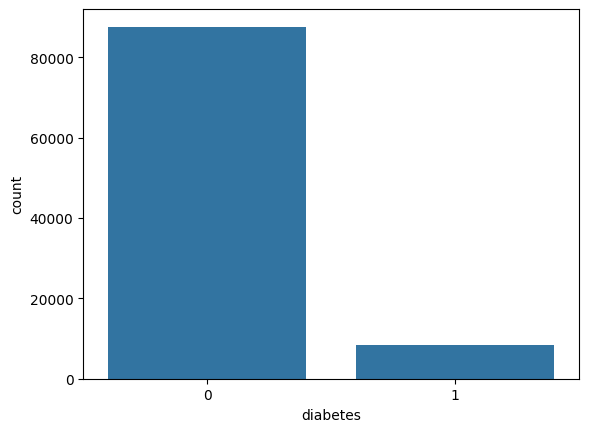

In [16]:
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [17]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [18]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.

X = df.drop(columns="diabetes")
y = df["diabetes"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTrain classes:")
print(y_train.value_counts())

print("\nTest classes:")
print(y_test.value_counts())

X_train: (76916, 8)
X_test: (19230, 8)

Train classes:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Test classes:
diabetes
0    17534
1     1696
Name: count, dtype: int64


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [19]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).
categorical_cols = [
    "gender",
    "smoking_history"
]

X_train = pd.get_dummies(
    X_train,
    columns=categorical_cols,
    drop_first=False,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_cols,
    drop_first=False,
    dtype=int
)

In [20]:
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print(X_train.shape)
print(X_test.shape)

(76916, 15)
(19230, 15)


In [21]:
# TODO: виведіть статистики опису X_train.
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.582675,0.417143,0.000182,0.342022,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493121,0.493090,0.013490,0.474390,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [22]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
train_corr = X_train.copy()
train_corr["diabetes"] = y_train

target_corr = train_corr.corr()["diabetes"].sort_values(
    key=abs,
    ascending=False
)

target_corr

,diabetes
diabetes,1.000000
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_No Info,-0.113053
smoking_history_former,0.096162
gender_Male,0.040650


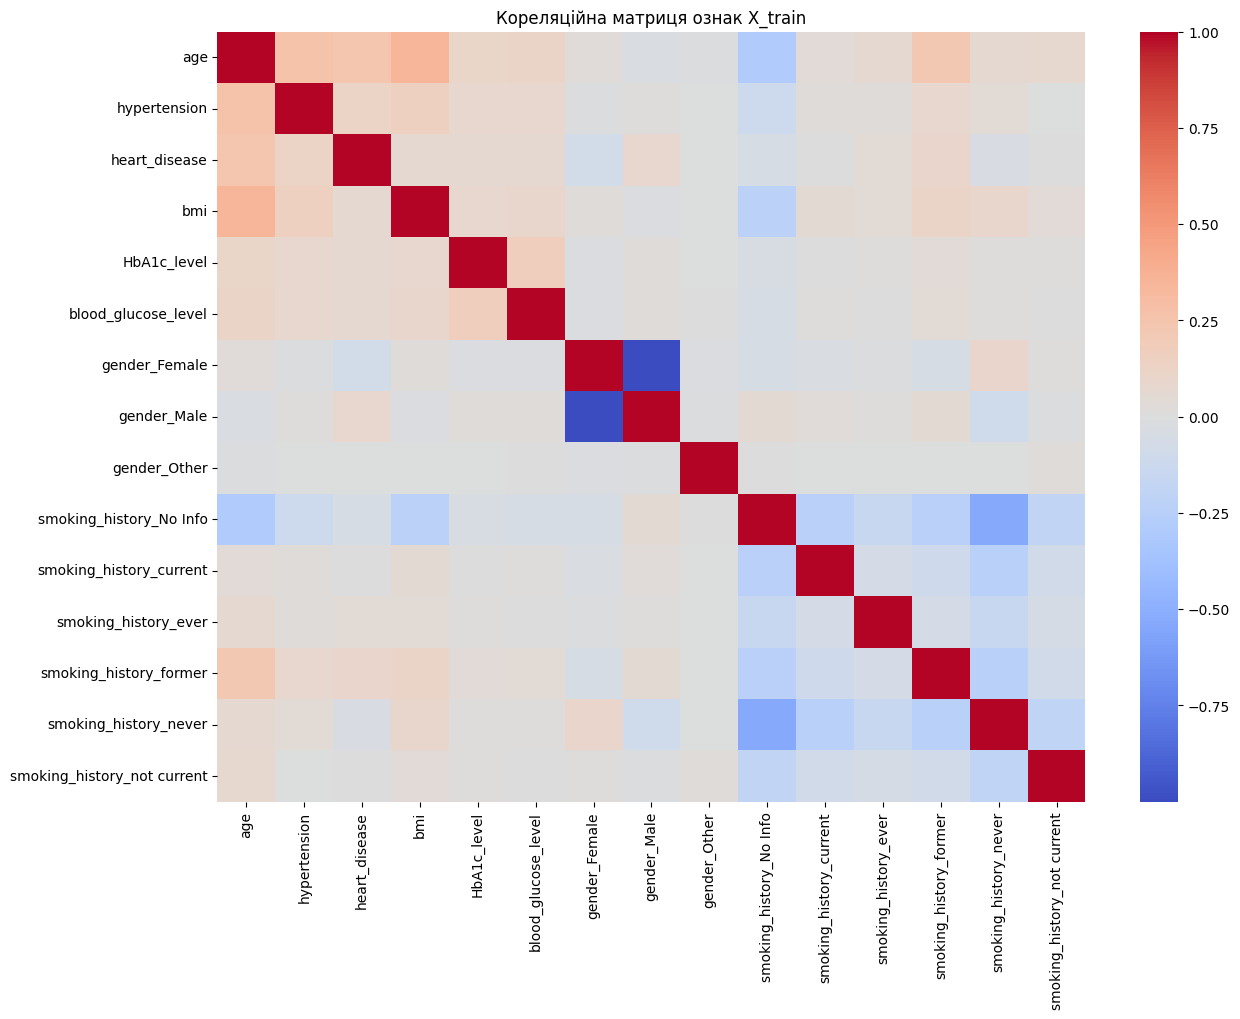

In [23]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).

corr_matrix = X_train.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Кореляційна матриця ознак X_train")
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

In [24]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.

continuous_cols = [
    "age",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
]

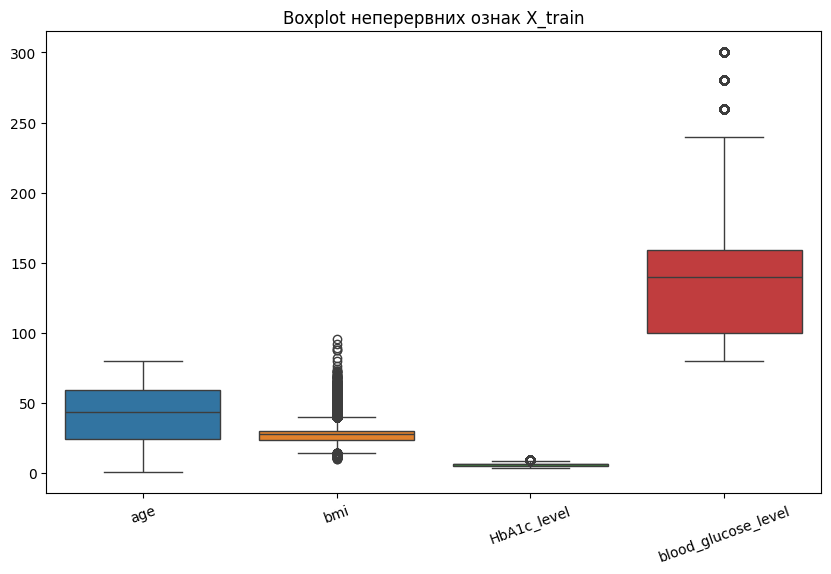

In [25]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=X_train[continuous_cols]
)

plt.title("Boxplot неперервних ознак X_train")
plt.xticks(rotation=20)

plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

Перевірити асиметрію розподілів ознак **на train**

In [26]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
skewness = X_train[
    continuous_cols
].skew().sort_values(
    key=abs,
    ascending=False
)

skewness

,0
bmi,1.005016
blood_glucose_level,0.830778
age,-0.061461
HbA1c_level,-0.055651


In [27]:
# TODO: перевірте пропуски окремо в X_train та X_test.

print("X_train:")
print(X_train.isnull().sum())

print("\nX_test:")
print(X_test.isnull().sum())

X_train:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64

X_test:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_hist

**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [28]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [29]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("До SMOTE:")
print(y_train.value_counts())

print("\nПісля SMOTE:")
print(y_train_balanced.value_counts())

До SMOTE:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Після SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [30]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Ridge Classifier": RidgeClassifier(),

    "SGD Classifier": SGDClassifier(
        random_state=42
    ),

    "SVC": SVC(
        kernel="linear",
        tol=1e-2,
        max_iter=2000,
        cache_size=4000,
        random_state=42
    )
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Logistic Regression
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



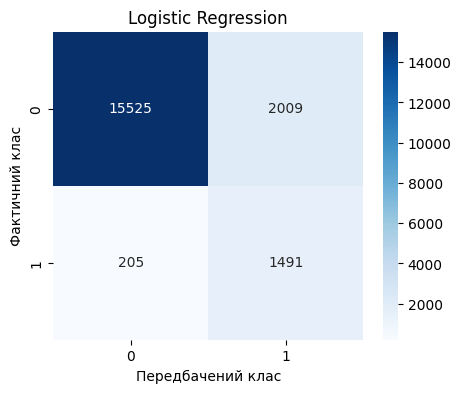


Ridge Classifier
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



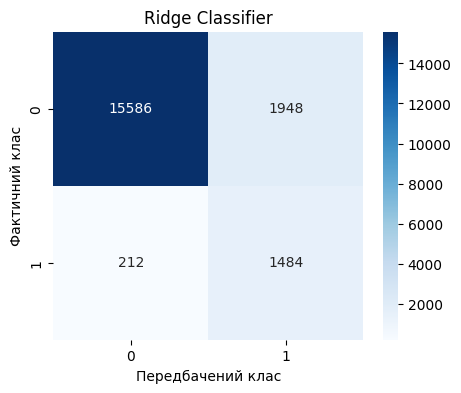


SGD Classifier
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.54      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



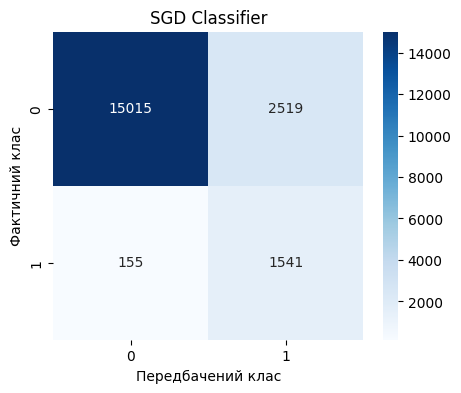


SVC


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


              precision    recall  f1-score   support

           0       0.99      0.14      0.24     17534
           1       0.10      0.98      0.18      1696

    accuracy                           0.21     19230
   macro avg       0.54      0.56      0.21     19230
weighted avg       0.91      0.21      0.24     19230



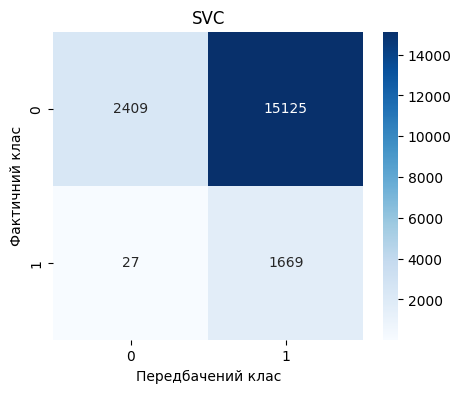

In [31]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).

predictions = {}

for name, model in models.items():
    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    model.fit(
        X_train_balanced,
        y_train_balanced
    )

    y_pred = model.predict(
        X_test_scaled
    )

    predictions[name] = y_pred

    print(
        classification_report(
            y_test,
            y_pred
        )
    )

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.xlabel("Передбачений клас")
    plt.ylabel("Фактичний клас")
    plt.title(name)

    plt.show()

Оптимізувати гіперпараметри


In [32]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.

param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10],
        "model__solver": ["liblinear", "lbfgs"]
    },

    "Ridge Classifier": {
        "model__alpha": [0.1, 1, 10]
    },

    "SGD Classifier": {
        "model__alpha": [0.0001, 0.001, 0.01],
        "model__loss": ["hinge", "log_loss"],
        "model__penalty": ["l2", "l1"]
    },

    "SVC": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"]
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [33]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [34]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.

best_models = {}
best_scores = {}

for name, model in models.items():
    print("\n" + "=" * 60)
    print("Підбір параметрів:", name)
    print("=" * 60)

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])

    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=3,
        scoring="f1",
        min_resources=300,
        n_jobs=-1,
        verbose=1
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print("Найкращі параметри:")
    print(search.best_params_)

    print("CV F1:")
    print(search.best_score_)

    y_pred = search.best_estimator_.predict(X_test)

    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            y_pred
        )
    )


Підбір параметрів: Logistic Regression
n_iterations: 2
n_required_iterations: 2
n_possible_iterations: 6
min_resources_: 300
max_resources_: 76916
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 6
n_resources: 300
Fitting 3 folds for each of 6 candidates, totalling 18 fits
----------
iter: 1
n_candidates: 2
n_resources: 900
Fitting 3 folds for each of 2 candidates, totalling 6 fits
Найкращі параметри:
{'model__C': 10, 'model__solver': 'lbfgs'}
CV F1:
0.6292994749135099

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230


Підбір параметрів: Ridge Classifier
n_iterations: 2
n_required_iterations: 2
n_possible_iterations: 6
min_resources_: 300
max_resources_: 76916
aggr

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Найкращі параметри:
{'model__C': 1, 'model__kernel': 'linear'}
CV F1:
0.5836471868992194

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.14      0.24     17534
           1       0.10      0.98      0.18      1696

    accuracy                           0.21     19230
   macro avg       0.54      0.56      0.21     19230
weighted avg       0.91      0.21      0.24     19230



Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [35]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.

best_model_name = max(
    best_scores,
    key=best_scores.get
)

best_model = best_models[
    best_model_name
]

print("Найкраща модель:", best_model_name)
print("CV F1:", best_scores[best_model_name])

Найкраща модель: Ridge Classifier
CV F1: 0.6329440666373016


In [36]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.

sample_indices = X_test.sample(
    10,
    random_state=42
).index

X_sample = X_test.loc[
    sample_indices
]

y_sample = y_test.loc[
    sample_indices
]

sample_pred = best_model.predict(
    X_sample
)

prediction_table = pd.DataFrame({
    "Index": sample_indices,
    "True_Class": y_sample.values,
    "Predicted_Class": sample_pred
})

prediction_table

,Index,True_Class,Predicted_Class
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

# Висновки
У роботі було виконано класифікацію для прогнозування наявності діабету. Після видалення дублікатів спостерігався значний дисбаланс класів: 87 664 об’єкти класу 0 та 8 482 — класу 1. Найсильніше з цільовою змінною корелювали blood_glucose_level і HbA1c_level. Потенційні викиди не видалялися, оскільки вони можуть бути клінічно важливими.

Для балансування навчальної вибірки було використано SMOTE. Серед базових моделей найкращий F1 для класу diabetes = 1 показав Ridge Classifier — 0.58. Після підбору гіперпараметрів методом HalvingGridSearchCV найкращою моделлю також став Ridge Classifier з alpha = 10 і CV F1 = 0.633. На 10 випадкових тестових записах модель правильно класифікувала 8 із 10 об’єктів.

Масштабування та SMOTE виконувалися тільки на навчальній вибірці, а test залишався незалежним, щоб уникнути витоку даних і отримати коректну оцінку якості моделі.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики